In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder

---
### Load And Understand The Dataset
---

In [41]:
df = pd.read_csv("Student_Performance.csv")

In [42]:
print("Dataset shape:", df.shape)

Dataset shape: (10000, 6)


In [43]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [44]:
df.tail()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
9995,1,49,Yes,4,2,23.0
9996,7,64,Yes,8,5,58.0
9997,6,83,Yes,8,5,74.0
9998,9,97,Yes,7,0,95.0
9999,7,74,No,8,1,64.0


In [45]:
print("Column names:")
df.columns.tolist()

Column names:


['Hours Studied',
 'Previous Scores',
 'Extracurricular Activities',
 'Sleep Hours',
 'Sample Question Papers Practiced',
 'Performance Index']

In [46]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 493.2 KB


In [47]:
print("Data types of each column:")
df.dtypes

Data types of each column:


Hours Studied                         int64
Previous Scores                       int64
Extracurricular Activities              str
Sleep Hours                           int64
Sample Question Papers Practiced      int64
Performance Index                   float64
dtype: object

In [48]:
print("Statistical summary:")
df.describe()

Statistical summary:


,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [49]:
print("Missing values in each column:")
df.isnull().sum()

Missing values in each column:


Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [50]:
print("Total missing values:")
print(df.isnull().sum().sum())

Total missing values:
0


In [51]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 127


In [52]:
df = df.drop_duplicates()
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


---
### Clean The Data
---

In [53]:
df_clean = df.copy()

In [54]:
numeric_cols = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

In [55]:
# Scores must be between 0 and 100
for col in ["Previous Scores", "Performance Index"]:
    df_clean.loc[
        (df_clean[col] < 0) | (df_clean[col] > 100),
        col
    ] = np.nan

# Study & Sleep hours cannot be negative
for col in ["Sleep Hours", "Hours Studied"]:
    df_clean.loc[df_clean[col] < 0, col] = np.nan

# Sample Papers cannot be negative
df_clean.loc[df_clean["Sample Question Papers Practiced"] < 0, "Sample Question Papers Practiced"] = np.nan

In [56]:
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

In [57]:
categorical_cols = [
    "Extracurricular Activities"
]

for col in categorical_cols:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace("", pd.NA)

    if df_clean[col].notna().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode().iloc[0]
        )
    else:
        df_clean[col] = df_clean[col].fillna("Unknown")

In [58]:
print("Missing values after cleaning:")
print(df_clean.isnull().sum())
print("\nDuplicate rows:", df_clean.duplicated().sum())
print("\nCleaned dataset shape:", df_clean.shape)

Missing values after cleaning:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Duplicate rows: 0

Cleaned dataset shape: (9873, 6)


---
### Detect Outliers
---

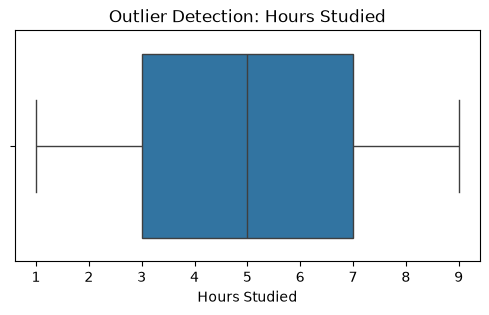

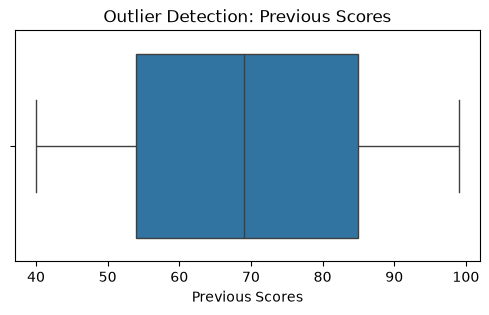

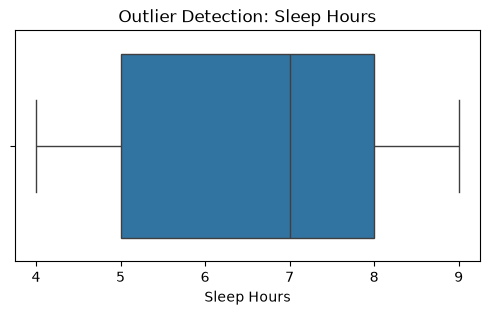

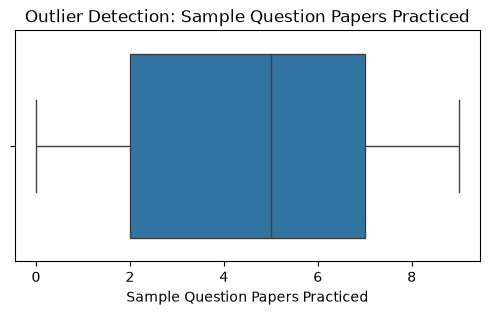

In [59]:
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df_clean[col])
    plt.title(f"Outlier Detection: {col}")
    plt.show()

In [60]:
for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df_clean[col] < lower_limit) |
        (df_clean[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of outliers:", len(outliers))

    display(outliers)


Column: Hours Studied
Lower limit: -3.0
Upper limit: 13.0
Number of outliers: 0


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index



Column: Previous Scores
Lower limit: 7.5
Upper limit: 131.5
Number of outliers: 0


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index



Column: Sleep Hours
Lower limit: 0.5
Upper limit: 12.5
Number of outliers: 0


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index



Column: Sample Question Papers Practiced
Lower limit: -5.5
Upper limit: 14.5
Number of outliers: 0


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index


---
### Analyze Relationships And Correlations
---

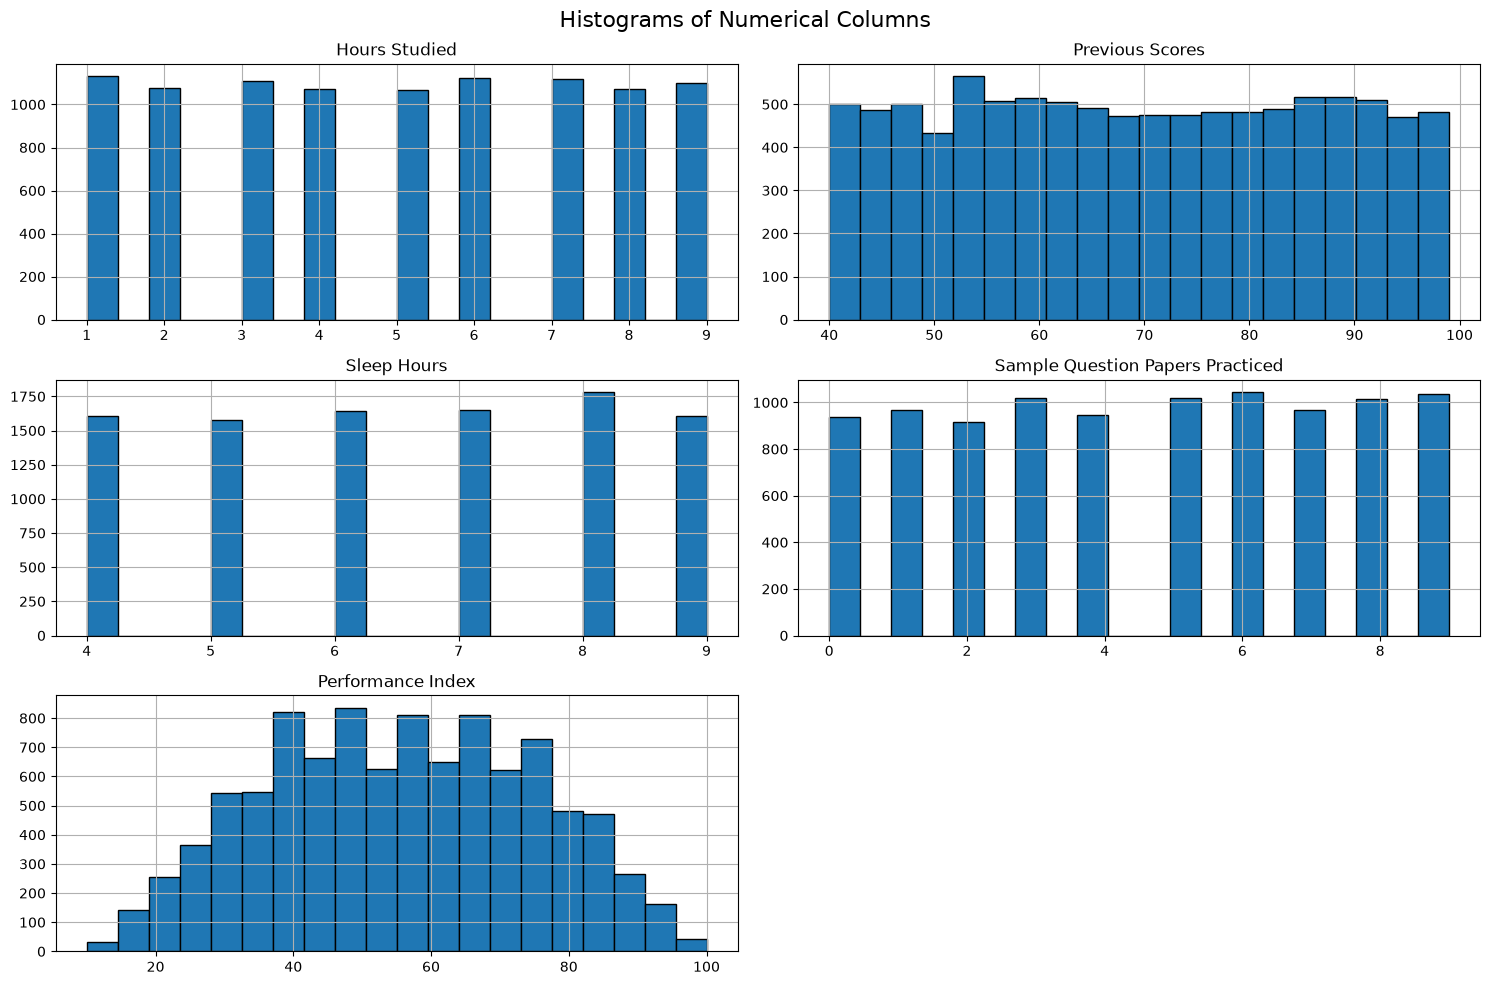

In [61]:
df_clean.hist(bins=20, figsize=(15, 10), edgecolor="black")

plt.suptitle("Histograms of Numerical Columns", fontsize=16)
plt.tight_layout()
plt.savefig("histogram_of_numerical_columns")
plt.show()

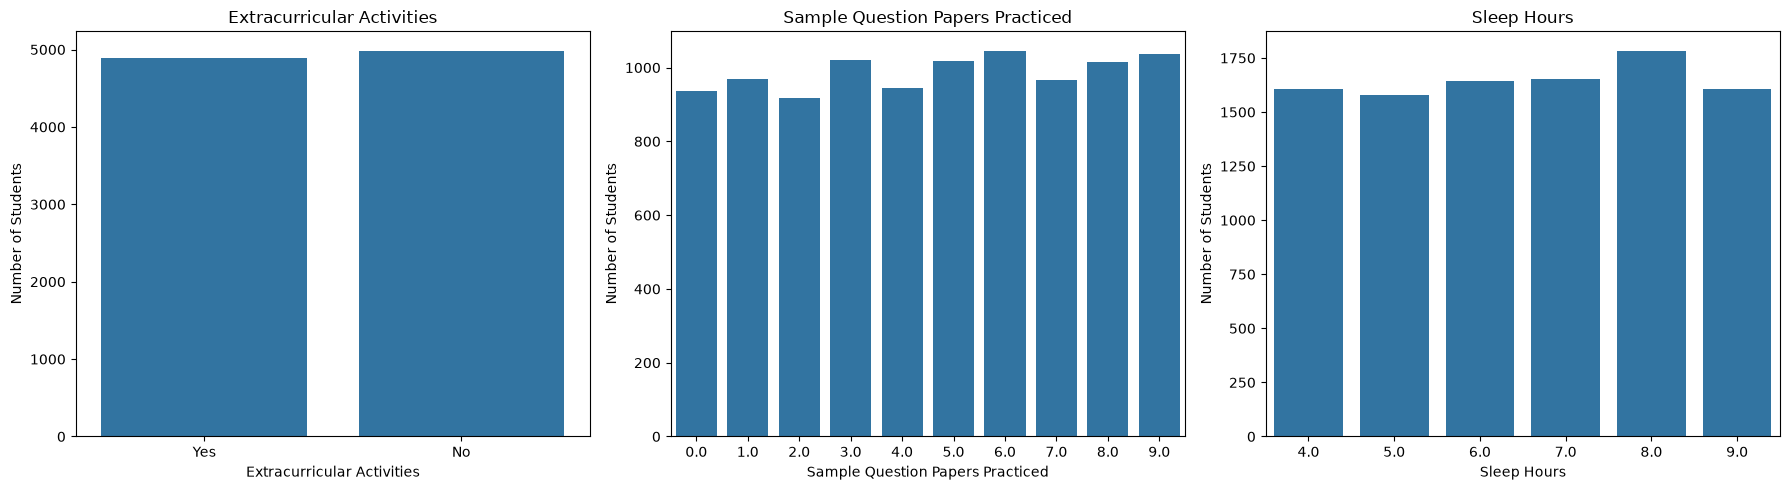

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df_clean, x="Extracurricular Activities", ax=axes[0])
axes[0].set_title("Extracurricular Activities")
axes[0].set_xlabel("Extracurricular Activities")
axes[0].set_ylabel("Number of Students")

sns.countplot(data=df_clean, x="Sample Question Papers Practiced", ax=axes[1])
axes[1].set_title("Sample Question Papers Practiced")
axes[1].set_xlabel("Sample Question Papers Practiced")
axes[1].set_ylabel("Number of Students")

sns.countplot(data=df_clean, x="Sleep Hours", ax=axes[2])
axes[2].set_title("Sleep Hours")
axes[2].set_xlabel("Sleep Hours")
axes[2].set_ylabel("Number of Students")

plt.tight_layout()
plt.savefig("box_plot_of_features")
plt.show()

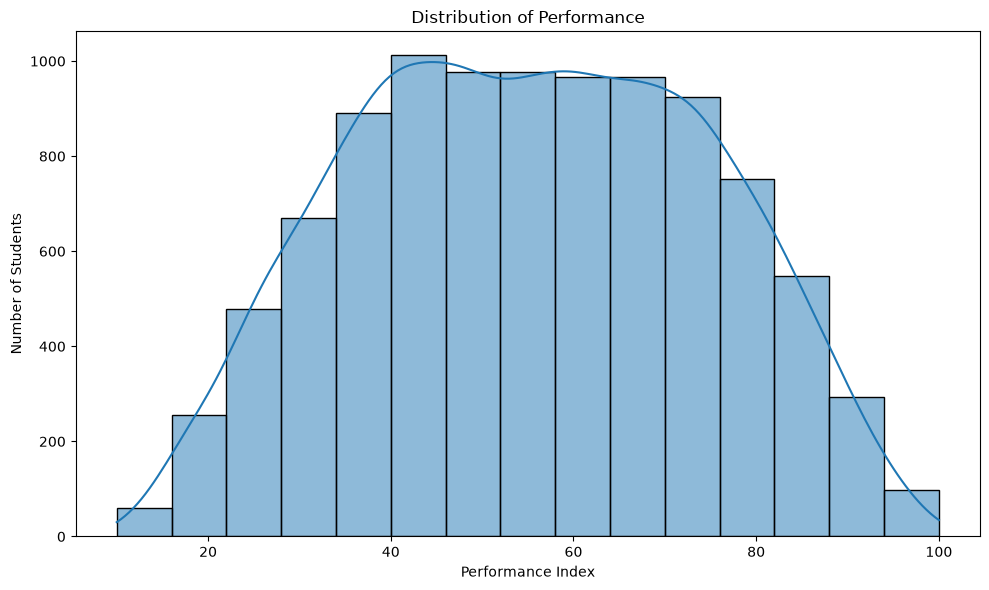

In [63]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df_clean["Performance Index"].dropna(),
    bins=15,
    kde=True
)

plt.title("Distribution of Performance")
plt.xlabel("Performance Index")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.savefig("distribution_of_performance")
plt.show()

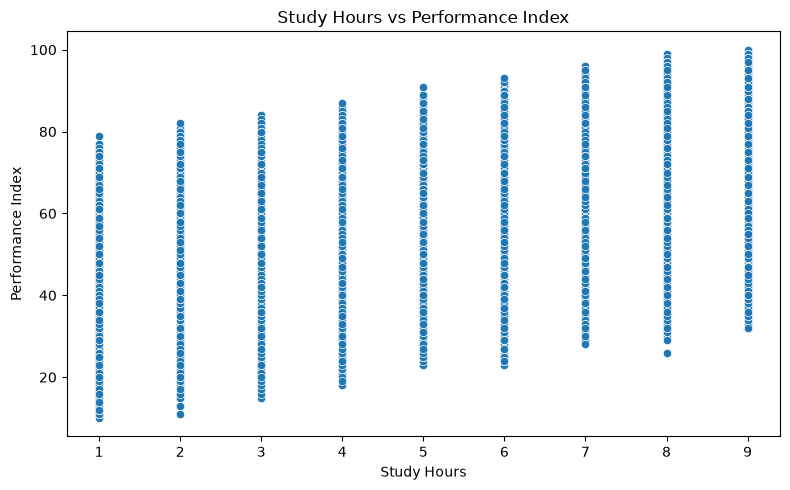

In [64]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Hours Studied",
    y="Performance Index"
)

plt.title("Study Hours vs Performance Index")
plt.xlabel("Study Hours")
plt.ylabel("Performance Index")
plt.tight_layout()
plt.savefig("study_hours_vs_performance_index")
plt.show()

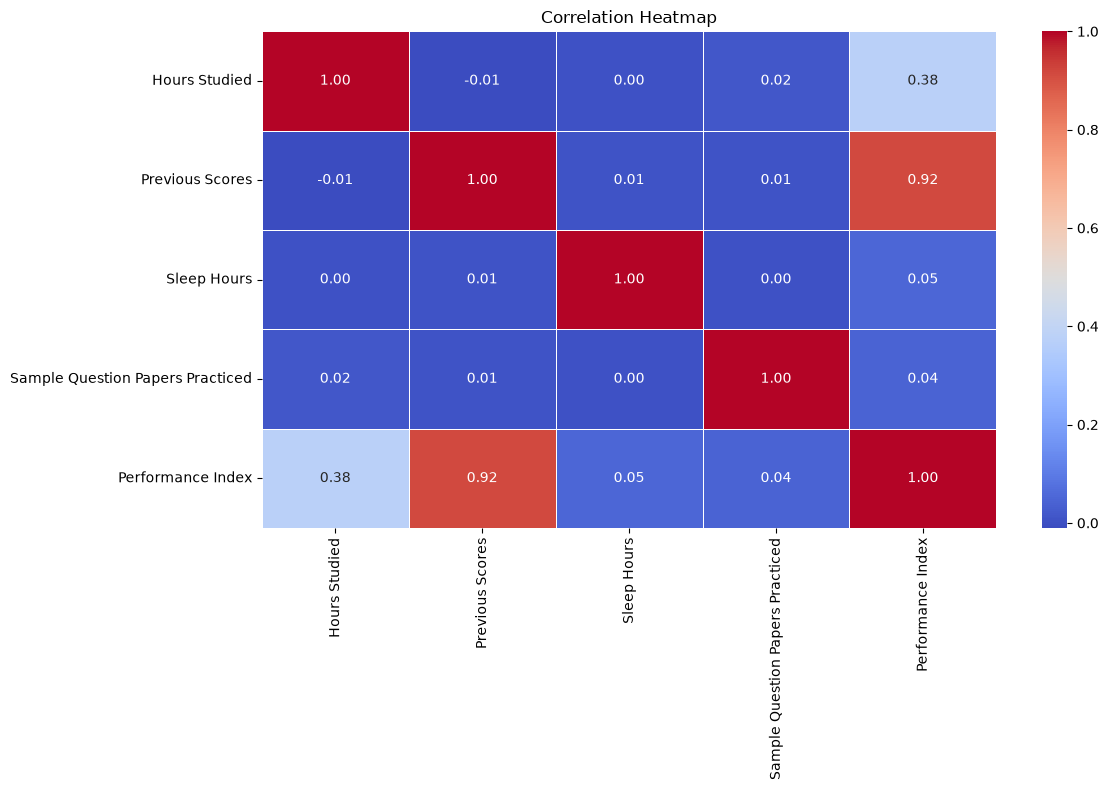

In [65]:
numeric_df = df_clean.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap")
plt.show()

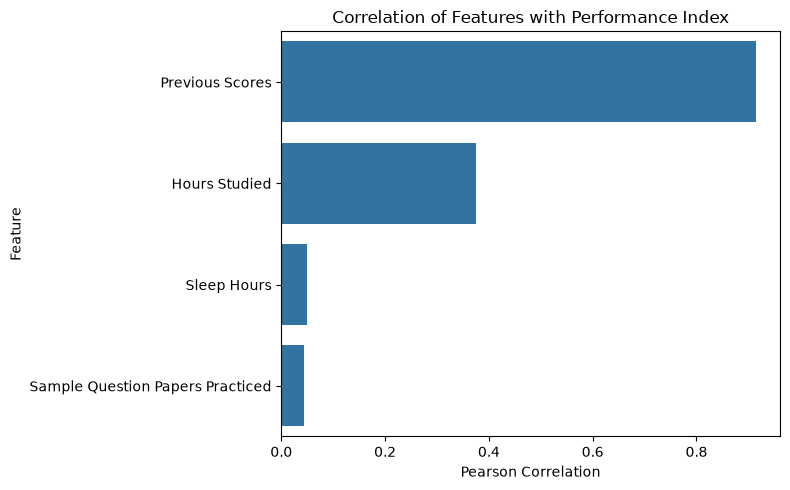

In [66]:
grade_corr = (
    correlation_matrix["Performance Index"]
    .drop("Performance Index")
    .sort_values(key=abs, ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=grade_corr.values,
    y=grade_corr.index
)

plt.title("Correlation of Features with Performance Index")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

---
### Encode Categorical Variables And Scale Numerical Features
---

In [67]:
df_clean.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7.0,99.0,Yes,9.0,1.0,91.0
1,4.0,82.0,No,4.0,2.0,65.0
2,8.0,51.0,Yes,7.0,2.0,45.0
3,5.0,52.0,Yes,5.0,2.0,36.0
4,7.0,75.0,No,8.0,5.0,66.0


In [68]:
df_clean["Extracurricular Activities"].value_counts()

Extracurricular Activities
No     4986
Yes    4887
Name: count, dtype: int64[pyarrow]

In [69]:
df_clean["Extracurricular Activities"] = df_clean["Extracurricular Activities"].map({"No":0,"Yes":1})


In [70]:
df_clean.rename(columns={"Extracurricular Activities":"is_doing_extra_activities"},inplace=True)
df_clean.head()

,Hours Studied,Previous Scores,is_doing_extra_activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7.0,99.0,1,9.0,1.0,91.0
1,4.0,82.0,0,4.0,2.0,65.0
2,8.0,51.0,1,7.0,2.0,45.0
3,5.0,52.0,1,5.0,2.0,36.0
4,7.0,75.0,0,8.0,5.0,66.0


---
### Feature Engineering
---

In [71]:
from sklearn.preprocessing import StandardScaler
cols = ["Hours Studied","Previous Scores","Sleep Hours","Sample Question Papers Practiced"]
scaler = StandardScaler()
df_clean[cols] = scaler.fit_transform(df_clean[cols])
df_clean.head()

,Hours Studied,Previous Scores,is_doing_extra_activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,0.775566,1.706168,1,1.454025,-1.249715,91.0
1,-0.383205,0.724912,0,-1.491315,-0.900925,65.0
2,1.161822,-1.064438,1,0.275889,-0.900925,45.0
3,0.003052,-1.006717,1,-0.902247,-0.900925,36.0
4,0.775566,0.320865,0,0.864957,0.145444,66.0


In [72]:
#Pearson Correlation  Calculation
from scipy.stats import pearsonr

selected_features = [
    "Hours Studied","Previous Scores","is_doing_extra_activities","Sleep Hours","Sample Question Papers Practiced"
]

correlations = {
    feature: pearsonr(df_clean[feature], df_clean['Performance Index'])[0]
    for feature in selected_features
}
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
1,Previous Scores,0.915135
0,Hours Studied,0.375332
3,Sleep Hours,0.050352
4,Sample Question Papers Practiced,0.043436
2,is_doing_extra_activities,0.026075


In [73]:
cat_features = ["is_doing_extra_activities"]

In [74]:
#Chi2_Statistic Test
from scipy.stats import chi2_contingency
import pandas as pd

alpha = 0.05

df_clean['Performance Index_bin'] = pd.qcut(df_clean['Performance Index'], q=4, labels=False)
chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(df_clean[col], df_clean['Performance Index_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,Decision
is_doing_extra_activities,11.332472,0.010057,Reject Null (Keep Feature)


In [75]:
df_clean.head()

,Hours Studied,Previous Scores,is_doing_extra_activities,Sleep Hours,Sample Question Papers Practiced,Performance Index,Performance Index_bin
0,0.775566,1.706168,1,1.454025,-1.249715,91.0,3
1,-0.383205,0.724912,0,-1.491315,-0.900925,65.0,2
2,1.161822,-1.064438,1,0.275889,-0.900925,45.0,1
3,0.003052,-1.006717,1,-0.902247,-0.900925,36.0,0
4,0.775566,0.320865,0,0.864957,0.145444,66.0,2


In [76]:
final_df1 = df_clean[["Hours Studied","Previous Scores","is_doing_extra_activities",'Sleep Hours','Sample Question Papers Practiced','Performance Index']]
final_df1

,Hours Studied,Previous Scores,is_doing_extra_activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,0.775566,1.706168,1,1.454025,-1.249715,91.0
1,-0.383205,0.724912,0,-1.491315,-0.900925,65.0
2,1.161822,-1.064438,1,0.275889,-0.900925,45.0
3,0.003052,-1.006717,1,-0.902247,-0.900925,36.0
4,0.775566,0.320865,0,0.864957,0.145444,66.0
...,...,...,...,...,...,...
9995,-1.541976,-1.179880,1,-1.491315,-0.900925,23.0
9996,0.775566,-0.314066,1,0.864957,0.145444,58.0
9997,0.389309,0.782633,1,0.864957,0.145444,74.0
9998,1.548079,1.590727,1,0.275889,-1.598505,95.0


In [77]:
final_df2 = df_clean[["Hours Studied","Previous Scores",'Sleep Hours','Sample Question Papers Practiced','Performance Index']]
final_df2

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,0.775566,1.706168,1.454025,-1.249715,91.0
1,-0.383205,0.724912,-1.491315,-0.900925,65.0
2,1.161822,-1.064438,0.275889,-0.900925,45.0
3,0.003052,-1.006717,-0.902247,-0.900925,36.0
4,0.775566,0.320865,0.864957,0.145444,66.0
...,...,...,...,...,...
9995,-1.541976,-1.179880,-1.491315,-0.900925,23.0
9996,0.775566,-0.314066,0.864957,0.145444,58.0
9997,0.389309,0.782633,0.864957,0.145444,74.0
9998,1.548079,1.590727,0.275889,-1.598505,95.0


In [78]:
final_df1.to_csv("student_performance_final1.csv", index=False)
final_df2.to_csv("student_performance_final2.csv", index=False)
print("Final dataset saved successfully!")

Final dataset saved successfully!
